In [ ]:
# Write a program to sharpen the input image using:
# 1. Laplacian filter
# 2. Gradient operators of Sobel and Canny edge detector
# 3. Unsharp masking. To obtain blurred image, use the Gaussian filter of size 5x5
# and sigma= 3

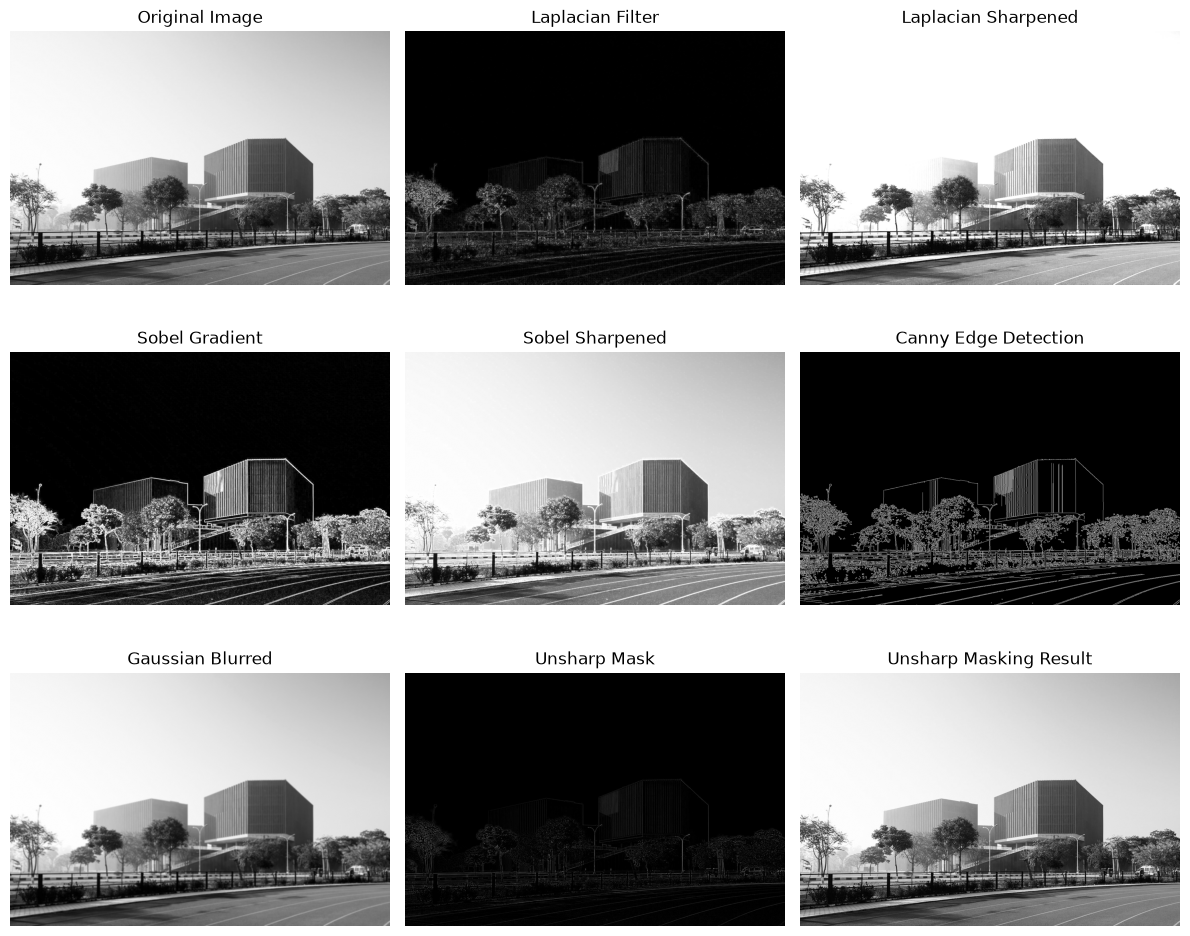

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input image
img = cv2.imread('image.jpg')

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


# 1. LAPLACIAN FILTER

laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

# Sharpen image using Laplacian
laplacian_sharp = cv2.addWeighted(gray, 1.5, laplacian, -0.5, 0)


# 2. GRADIENT OPERATORS

# Sobel X and Y
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Calculate Sobel gradient magnitude
sobel = np.sqrt(sobel_x**2 + sobel_y**2)
sobel = cv2.convertScaleAbs(sobel)

# Sharpen image using Sobel
sobel_sharp = cv2.addWeighted(gray, 1.0, sobel, 0.5, 0)

# Canny Edge Detection
canny = cv2.Canny(gray, 100, 200)


# 3. UNSHARP MASKING

# Apply Gaussian Blur (5x5, sigma=3)
blurred = cv2.GaussianBlur(gray, (5, 5), 3)

# Subtract blurred image from original
mask = cv2.subtract(gray, blurred)

# Add mask to original image
unsharp = cv2.addWeighted(gray, 1.5, blurred, -0.5, 0)


# DISPLAY ALL RESULTS

plt.figure(figsize=(12, 10))

plt.subplot(3, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(3, 3, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Filter')
plt.axis('off')

plt.subplot(3, 3, 3)
plt.imshow(laplacian_sharp, cmap='gray')
plt.title('Laplacian Sharpened')
plt.axis('off')

plt.subplot(3, 3, 4)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Gradient')
plt.axis('off')

plt.subplot(3, 3, 5)
plt.imshow(sobel_sharp, cmap='gray')
plt.title('Sobel Sharpened')
plt.axis('off')

plt.subplot(3, 3, 6)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.subplot(3, 3, 7)
plt.imshow(blurred, cmap='gray')
plt.title('Gaussian Blurred')
plt.axis('off')

plt.subplot(3, 3, 8)
plt.imshow(mask, cmap='gray')
plt.title('Unsharp Mask')
plt.axis('off')

plt.subplot(3, 3, 9)
plt.imshow(unsharp, cmap='gray')
plt.title('Unsharp Masking Result')
plt.axis('off')

plt.tight_layout()
plt.show()
